# 02 – Preprocessing

**Project:** Energy-Aware Early Fault Detection in Semiconductor Wafer Fabrication (UCI SECOM)

Steps:

1. **Time-ordered split** – first 80% of wafers (by timestamp) = train, last 20% = test. No shuffling.
2. **Preprocessing pipeline**, fitted on the **training set only**:

| # | Step | Learned from train | Why |
|---|---|---|---|
| 1 | Drop constant features | which columns have ≤ 1 unique value | carry no information |
| 2 | Drop features > 50% missing | missing rate per column | too sparse to impute reliably |
| 3 | Median imputation | per-feature medians | robust to the heavy skew/outliers seen in EDA |
| 4 | Pre-scaling (standardise) | means / SDs | numerical stability for step 5 (see below) |
| 5 | Yeo-Johnson transform | one λ per feature | reduce skew; works with zero/negative values |
| 6 | Standard scaling | means / SDs | zero mean, unit variance for linear models |
| 7 | Drop one of each pair with \|r\| > 0.95 | correlation matrix | remove near-duplicate sensors |

3. Sanity and leakage checks, then save the fitted pipeline to `outputs/models/`.

> **Why the extra pre-scaling step?** Many SECOM sensors have large raw values with a small spread
> (e.g. ~400 ± 10). Fitting Yeo-Johnson directly on those gives extreme λ values (down to about −47), which
> squashes the column to a numerically constant value and destroys it (17 features were lost this way when
> we tried it). Standardising first fixes this without changing the method.

In [1]:
import sys
from pathlib import Path

# Make the project root importable so `src` works from notebooks/
ROOT = Path.cwd().resolve().parent if Path.cwd().name == 'notebooks' else Path.cwd().resolve()
if str(ROOT) not in sys.path:
    sys.path.insert(0, str(ROOT))

import json
import time
import joblib
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.ticker as mtick

from src.config import RANDOM_STATE, MODELS_DIR, TIME_COL
from src.data_loader import load_secom, split_xy
from src.preprocessing import time_train_test_split, build_preprocessing_pipeline
from src.plotting import (apply_style, save_fig, PASS_COLOR, FAIL_COLOR, CATEGORICAL,
                          REF_LINE_COLOR, TEXT_SECONDARY, SURFACE)

np.random.seed(RANDOM_STATE)
apply_style()
MODELS_DIR.mkdir(parents=True, exist_ok=True)

df = load_secom()
print(df.shape)

(1567, 593)


## 1. Time-ordered train/test split (80 / 20)

`load_secom()` already sorts wafers by timestamp, so the first 80% of rows are the earliest wafers.

In [2]:
train_df, test_df = time_train_test_split(df, test_size=0.2)
X_train, y_train = split_xy(train_df)
X_test, y_test = split_xy(test_df)

split_info = pd.DataFrame({
    'wafers': [len(train_df), len(test_df)],
    'fails': [int(y_train.sum()), int(y_test.sum())],
    'fail_rate_%': [round(y_train.mean() * 100, 2), round(y_test.mean() * 100, 2)],
    'first_wafer': [train_df[TIME_COL].min(), test_df[TIME_COL].min()],
    'last_wafer': [train_df[TIME_COL].max(), test_df[TIME_COL].max()],
}, index=['train', 'test'])
print(split_info.to_string())

assert train_df[TIME_COL].max() <= test_df[TIME_COL].min(), 'test must come after train'
print('\nOK: every test wafer is later than every training wafer.')

       wafers  fails  fail_rate_%         first_wafer          last_wafer
train    1254     87         6.94 2008-07-19 11:55:00 2008-10-02 20:54:00
test      313     17         5.43 2008-10-02 21:32:00 2008-10-17 06:07:00

OK: every test wafer is later than every training wafer.


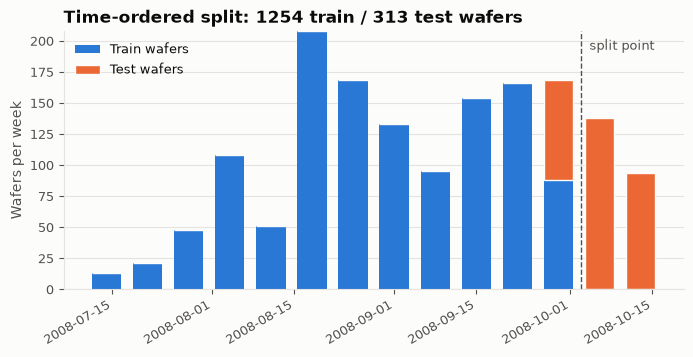

In [3]:
# Weekly wafer counts coloured by split, with the weekly fail rate
week = df[TIME_COL].dt.to_period('W').dt.start_time
weekly = df.assign(week=week, split=np.where(df.index < len(train_df), 'train', 'test')) \
           .groupby(['week', 'split'])['label'].agg(['size', 'sum']).reset_index()

counts = weekly.pivot(index='week', columns='split', values='size').fillna(0)[['train', 'test']]

fig, ax = plt.subplots(figsize=(8, 3.8))
ax.bar(counts.index, counts['train'], width=5, color=CATEGORICAL[0], label='Train wafers')
ax.bar(counts.index, counts['test'], width=5, bottom=counts['train'], color=CATEGORICAL[1], label='Test wafers',
       edgecolor=SURFACE, linewidth=1)   # stacked: the split week holds both
ax.axvline(test_df[TIME_COL].min(), color=REF_LINE_COLOR, linestyle='--', linewidth=1)
ax.text(test_df[TIME_COL].min(), ax.get_ylim()[1] * 0.97, '  split point', va='top', fontsize=9, color=TEXT_SECONDARY)
ax.set_ylabel('Wafers per week')
ax.set_title(f'Time-ordered split: {len(train_df)} train / {len(test_df)} test wafers')
ax.legend(loc='upper left')
ax.grid(axis='x', visible=False)
fig.autofmt_xdate()
save_fig(fig, '02_time_split')
plt.show()

The test period (the last ~2 weeks) has a fail rate close to the training rate, so the split is usable. Because both
sets are imbalanced, all later evaluation uses recall, PR-AUC and the cost metric rather than accuracy.

## 2. Build and fit the pipeline on the training set only

In [4]:
pipeline = build_preprocessing_pipeline(missing_threshold=0.5, corr_threshold=0.95)
t0 = time.time()
pipeline.fit(X_train)          # <- the ONLY fit; the test set is never seen here
print(f'Fitted in {time.time() - t0:.1f} s')
pipeline

Fitted in 8.0 s


Pipeline(steps=[('drop_constant', DropConstant()),
                ('drop_missing', DropHighMissing()),
                ('impute', SimpleImputer(strategy='median')),
                ('pre_scale', StandardScaler()),
                ('yeo_johnson', PowerTransformer(standardize=False)),
                ('scale', StandardScaler()),
                ('drop_correlated', DropCorrelated())])

In [5]:
X_train_p = pipeline.transform(X_train)
X_test_p = pipeline.transform(X_test)
print('Train:', X_train.shape, '->', X_train_p.shape)
print('Test :', X_test.shape, '->', X_test_p.shape)

Train: (1254, 590) -> (1254, 280)
Test : (313, 590) -> (313, 280)


## 3. Features removed at each step

             step  removed  remaining
      Raw sensors        0        590
    Drop constant      122        468
Drop >50% missing       24        444
  Drop |r| > 0.95      164        280

Final: 280 of 590 sensors kept (47%).


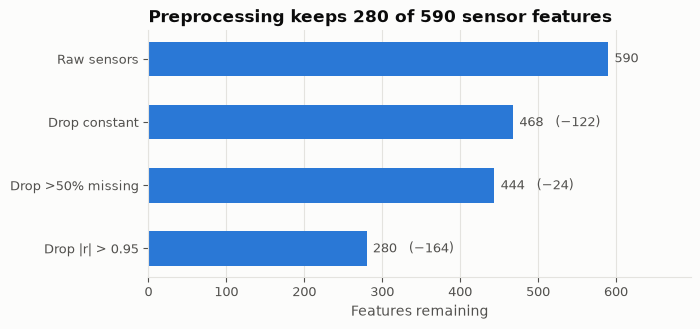

In [6]:
steps = pipeline.named_steps
n_raw = X_train.shape[1]
n_after_const = len(steps['drop_constant'].keep_)
n_after_missing = len(steps['drop_missing'].keep_)
n_final = len(steps['drop_correlated'].keep_)

funnel = pd.DataFrame({
    'step': ['Raw sensors', 'Drop constant', 'Drop >50% missing', 'Drop |r| > 0.95'],
    'removed': [0, n_raw - n_after_const, n_after_const - n_after_missing, n_after_missing - n_final],
    'remaining': [n_raw, n_after_const, n_after_missing, n_final],
})
print(funnel.to_string(index=False))
print(f'\nFinal: {n_final} of {n_raw} sensors kept ({n_final / n_raw:.0%}).')

fig, ax = plt.subplots(figsize=(7, 3.2))
ax.barh(funnel['step'][::-1], funnel['remaining'][::-1], color=CATEGORICAL[0], height=0.55)
for i, (rem, rm) in enumerate(zip(funnel['remaining'][::-1], funnel['removed'][::-1])):
    label = f'{rem}' + (f'   (−{rm})' if rm else '')
    ax.text(rem + 8, i, label, va='center', fontsize=9, color=TEXT_SECONDARY)
ax.set_xlim(0, n_raw * 1.18)
ax.set_xlabel('Features remaining')
ax.set_title(f'Preprocessing keeps {n_final} of {n_raw} sensor features')
ax.grid(axis='y', visible=False)
save_fig(fig, '02_feature_funnel')
plt.show()

In [7]:
dc = steps['drop_correlated']
examples = pd.Series(dc.drop_map_, name='kept (near-duplicate of dropped)').head(10)
print(f'{len(dc.drop_map_)} features dropped as near-duplicates. Examples (dropped -> kept):')
print(examples.to_string())

164 features dropped as near-duplicates. Examples (dropped -> kept):
f036    f034
f096    f094
f104    f099
f105    f092
f106    f093
f127    f122
f154    f148
f174    f172
f201    f196
f249    f114


More features are removed as near-duplicates here than the raw-data EDA suggested, because after imputation and
Yeo-Johnson many relationships between sensors become more linear, so more pairs pass |r| > 0.95.

## 4. Effect of Yeo-Johnson on skewness

|skew| > 1 before: 175 of 280
|skew| > 1 after : 13 of 280
Median |skew| before 1.83 -> after 0.08
Yeo-Johnson lambda range: -55.38 to 5.15 (median 0.28)


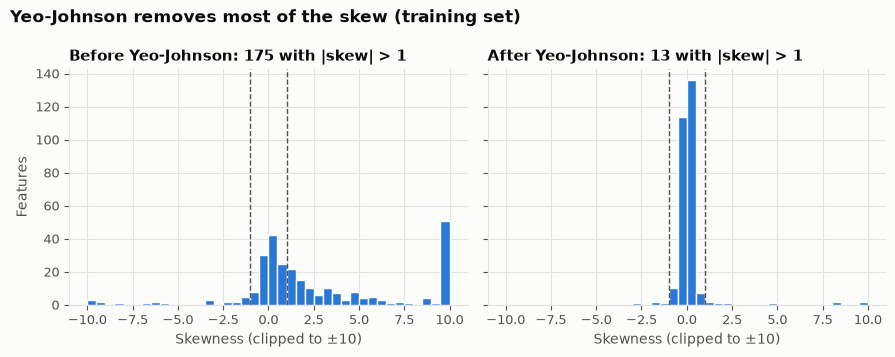

In [8]:
# Skewness of the kept features right after imputation (before transform) vs. final output
after_impute = pipeline[:3].transform(X_train)[X_train_p.columns]
skew_before = after_impute.skew()
skew_after = X_train_p.skew()

print(f'|skew| > 1 before: {(skew_before.abs() > 1).sum()} of {len(skew_before)}')
print(f'|skew| > 1 after : {(skew_after.abs() > 1).sum()} of {len(skew_after)}')
print(f'Median |skew| before {skew_before.abs().median():.2f} -> after {skew_after.abs().median():.2f}')

lam = pd.Series(steps['yeo_johnson'].lambdas_, index=steps['pre_scale'].get_feature_names_out())
print(f'Yeo-Johnson lambda range: {lam.min():.2f} to {lam.max():.2f} (median {lam.median():.2f})')

fig, axes = plt.subplots(1, 2, figsize=(9, 3.6), sharey=True)
bins = np.arange(-10, 10.5, 0.5)
for ax, s, title in [(axes[0], skew_before, 'Before Yeo-Johnson'), (axes[1], skew_after, 'After Yeo-Johnson')]:
    ax.hist(s.clip(-10, 10), bins=bins, color=CATEGORICAL[0], edgecolor='white', linewidth=1)
    for t in (-1, 1):
        ax.axvline(t, color=REF_LINE_COLOR, linestyle='--', linewidth=1)
    ax.set_title(f'{title}: {(s.abs() > 1).sum()} with |skew| > 1', fontsize=11)
    ax.set_xlabel('Skewness (clipped to ±10)')
axes[0].set_ylabel('Features')
fig.suptitle('Yeo-Johnson removes most of the skew (training set)', x=0.01, ha='left', fontweight='bold')
fig.tight_layout()
save_fig(fig, '02_skewness_before_after')
plt.show()

## 5. Sanity and leakage checks

In [9]:
checks = {
    'No missing values in train output': not X_train_p.isna().any().any(),
    'No missing values in test output': not X_test_p.isna().any().any(),
    'All values finite (train and test)': bool(np.isfinite(X_train_p.values).all() and np.isfinite(X_test_p.values).all()),
    'Same columns in train and test': list(X_train_p.columns) == list(X_test_p.columns),
    'No zero-variance columns in train': bool((X_train_p.std() > 1e-6).all()),
    'Train means ~ 0 and SDs ~ 1': bool(np.allclose(X_train_p.mean(), 0, atol=1e-6) and np.allclose(X_train_p.std(ddof=0), 1, atol=1e-6)),
    'Kept columns are original sensor names': all(c.startswith('f') for c in X_train_p.columns),
}
for k, v in checks.items():
    print(f"{'PASS' if v else 'FAIL'}  {k}")
assert all(checks.values())

# Leakage check: a fresh pipeline fitted on X_train alone (test never passed to fit) reproduces the output exactly.
same = build_preprocessing_pipeline().fit(X_train).transform(X_test).equals(X_test_p)
print(f"{'PASS' if same else 'FAIL'}  A pipeline fitted on train alone reproduces the test output")

PASS  No missing values in train output
PASS  No missing values in test output
PASS  All values finite (train and test)
PASS  Same columns in train and test
PASS  No zero-variance columns in train
PASS  Train means ~ 0 and SDs ~ 1
PASS  Kept columns are original sensor names


PASS  A pipeline fitted on train alone reproduces the test output


In [10]:
# Test-set drift: values far outside what the pipeline saw in training
z_test = X_test_p.abs()
extreme = (z_test > 10)
print(f'Test cells with |z| > 10: {int(extreme.values.sum())} '
      f'in {int(extreme.any().sum())} features and {int(extreme.any(axis=1).sum())} wafers')
print('\nLargest test values (in training SDs):')
print(z_test.max().sort_values(ascending=False).head(5).round(1).to_string())

Test cells with |z| > 10: 44 in 13 features and 32 wafers

Largest test values (in training SDs):
f004    121.4
f007     67.0
f053     32.5
f031     26.0
f054     18.4


A few test wafers have readings far outside the training range (one sensor reaches over 100 training SDs).
This is genuine drift or sensor anomalies in the later period, not a bug: the pipeline only uses training
statistics. We keep these values (an extreme reading may be exactly what signals a fault) but note that
linear models can be sensitive to them; tree models are not. 04_Modelling can compare both.

## 6. Save the fitted pipeline

In [11]:
pipeline_path = MODELS_DIR / 'preprocessing_pipeline.joblib'
joblib.dump(pipeline, pipeline_path)

summary = {
    'random_state': RANDOM_STATE,
    'split': {
        'method': 'time-ordered, first 80% train / last 20% test, no shuffling',
        'n_train': len(train_df), 'n_test': len(test_df),
        'train_fails': int(y_train.sum()), 'test_fails': int(y_test.sum()),
        'train_end': str(train_df[TIME_COL].max()), 'test_start': str(test_df[TIME_COL].min()),
    },
    'n_features_raw': n_raw,
    'dropped_constant': steps['drop_constant'].dropped_,
    'dropped_high_missing': steps['drop_missing'].dropped_,
    'dropped_correlated': dc.drop_map_,
    'kept_features': list(X_train_p.columns),
}
summary_path = MODELS_DIR / 'preprocessing_summary.json'
summary_path.write_text(json.dumps(summary, indent=2))

print('Saved:')
print(' ', pipeline_path.relative_to(ROOT), f'({pipeline_path.stat().st_size / 1024:.0f} KB)')
print(' ', summary_path.relative_to(ROOT))

# Round-trip check
reloaded = joblib.load(pipeline_path)
assert reloaded.transform(X_test).equals(X_test_p)
print('Reloaded pipeline gives identical output.')

Saved:
  outputs\models\preprocessing_pipeline.joblib (83 KB)
  outputs\models\preprocessing_summary.json
Reloaded pipeline gives identical output.


### Summary

- Train = earliest 80% of wafers, test = latest 20%; no shuffling, no overlap in time.
- The pipeline is fitted on training data only and saved as one object, so 03–06 apply exactly the same steps
  with `joblib.load(...).transform(X)`.
- Loading it requires `src/preprocessing.py` to be importable (the custom drop steps live there).